# 01 — Preprocessing exploration

Exploration only: training uses `DataManager` (`src/datasets.py`), which applies the same steps to every model.

| Step here | In training |
|---|---|
| Skip corrupt / < `min_side` images | Same (`_build_manifest`) |
| Drop exact pHash duplicates | Stricter: near-duplicate groups (Hamming ≤ 5), one image kept per group, conflicting-label groups dropped (`_clean`) |
| Bilinear resize to 224 | Same (`get_dataset`) |
| Divide by 255 | **Not applied on purpose**: each backbone normalises raw 0–255 pixels itself (EfficientNetV2 built-in rescaling, ConvNeXtV2 ImageNet mean/std). Feeding 0–1 images would break both. |

In [ ]:
# Bootstrap: same cell works on a local kernel and on a Colab kernel (VS Code Colab extension).
# On Colab the code runs on Google's VM, which only sees what is *pushed* to GitHub:
# commit + push your changes, set BRANCH, then run this cell.
import os
import subprocess
import sys
from pathlib import Path

BRANCH = "feat/convNext-baseline"
REPO_URL = "https://github.com/LeafLab-AI/plant-disease-tl.git"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_ROOT = Path("/content/plant-disease-tl")
    git = ["git", "-C", str(PROJECT_ROOT)]
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}  # fail fast instead of hanging on a prompt
    if not (PROJECT_ROOT / ".git").exists():
        cmds = [["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(PROJECT_ROOT)]]
    else:
        cmds = [[*git, "fetch", "-q", "origin", BRANCH], [*git, "checkout", "-q", "-B", BRANCH, "FETCH_HEAD"]]
    for cmd in cmds:
        if subprocess.run(cmd, env=env).returncode != 0:
            raise RuntimeError(f"git failed for branch '{BRANCH}': is it pushed, and is the repo public?")
else:
    PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if IN_COLAB:
    from src.colab import setup_runtime
    setup_runtime()
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

In [1]:
import os
import json
from pathlib import Path
import yaml
import imagehash
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf

with open("configs/base.yaml", "r") as f:
    cfg = yaml.safe_load(f)

RAW_DIR = Path("data/raw/Plant_Leaf_Diseases")
IMG_SIZE = int(cfg["data"]["img_size"])        # 224
MIN_SIDE = int(cfg["data"]["min_side"])        # 96
VALID_EXTS = {ext.lower() for ext in cfg["data"]["image_exts"]}

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Dir Exists: {RAW_DIR.exists()} | Target Size: {IMG_SIZE}x{IMG_SIZE}")

I0000 00:00:1794588936.596243   11572 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Project Root: /home/ambitiousflow/projects/plant-disease-tl
Dataset Dir Exists: True | Target Size: 224x224


In [2]:
records = []
corrupted, too_small = 0, 0

for img_path in sorted(RAW_DIR.rglob("*")):
    if not img_path.is_file() or img_path.suffix.lower() not in VALID_EXTS:
        continue
    try:
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            w, h = img.size
            if min(w, h) < MIN_SIDE:
                too_small += 1
                continue
            phash_val = str(imagehash.phash(img, hash_size=cfg["data"]["dedup"]["hash_size"]))
    except (OSError, ValueError):
        corrupted += 1
        continue

    records.append({
        "path": str(img_path),
        "label": img_path.parent.name,
        "width": w,
        "height": h,
        "phash": phash_val,
    })

manifest_df = pd.DataFrame(records)
clean_df = manifest_df.drop_duplicates(subset=["phash"]).reset_index(drop=True)

print(f"Scanned: {len(manifest_df) + corrupted + too_small}")
print(f"Corrupted: {corrupted} | Too Small (<{MIN_SIDE}px): {too_small}")
print(f"Exact pHash Duplicates Removed: {len(manifest_df) - len(clean_df)}")
print(f"Clean Images Remaining: {len(clean_df)} across {clean_df['label'].nunique()} classes")
display(clean_df["label"].value_counts())

Scanned: 40223
Corrupted: 0 | Too Small (<96px): 0
Exact pHash Duplicates Removed: 4593
Clean Images Remaining: 35630 across 21 classes


label
Tomato___Late_Blight               3040
Tomato___Bacterial_Spot            2813
Tomato___Septoria_Leaf_Spot        2745
Tomato___Healthy                   2644
Tomato___Yellow_Leaf_Curl_Virus    2286
Grape___Black_Measles              2271
Tomato___Spider_Mites              2013
Tomato___Target_Spot               1981
Tomato___Early_Blight              1857
Tomato___Leaf_Mold                 1850
Tomato___Mosaic_Virus              1657
Grape___Healthy                    1305
Corn___Common_Rust                 1192
Grape___Black_Rot                  1180
Corn___Healthy                     1161
Grape___Leaf_Blight                1076
Potato___Early_Blight              1000
Potato___Late_Blight               1000
Potato___Healthy                    999
Corn___Northern_Leaf_Blight         986
Corn___Gray_Leaf_Spot               574
Name: count, dtype: int64

In [ ]:
def decode_resize_normalize(path: tf.Tensor) -> tf.Tensor:
    
    raw_bytes = tf.io.read_file(path)
    img = tf.io.decode_image(raw_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img

classes = sorted(clean_df["label"].unique().tolist())
class_to_idx = {c: i for i, c in enumerate(classes)}

paths = clean_df["path"].values
labels = np.array([class_to_idx[l] for l in clean_df["label"]], dtype=np.int32)

test_ds = (
    tf.data.Dataset.from_tensor_slices((paths, labels))
    .shuffle(1000, seed=cfg["seed"])
    .map(lambda p, y: (decode_resize_normalize(p), y), num_parallel_calls=4)
    .batch(16)
    .prefetch(2)
)

batch_imgs, batch_lbls = next(iter(test_ds))
print("Batch Tensor Shape:", batch_imgs.shape)
print("Dtype:", batch_imgs.dtype)
print(f"Min Pixel: {batch_imgs.numpy().min():.4f} | Max Pixel: {batch_imgs.numpy().max():.4f}")

I0000 00:00:1794589042.201236   11572 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5590 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6
E0000 00:00:1794589042.386977   11572 cuda_executor.cc:1365] [0] Failed to allocate device memory of 5.46GiB (5861539840 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E0000 00:00:1794589042.391205   11572 cuda_executor.cc:1365] [0] Failed to allocate device memory of 4.91GiB (5275385856 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
exte

Batch Tensor Shape: (16, 224, 224, 3)
Dtype: <dtype: 'float32'>
Min Pixel: 0.0000 | Max Pixel: 1.0000


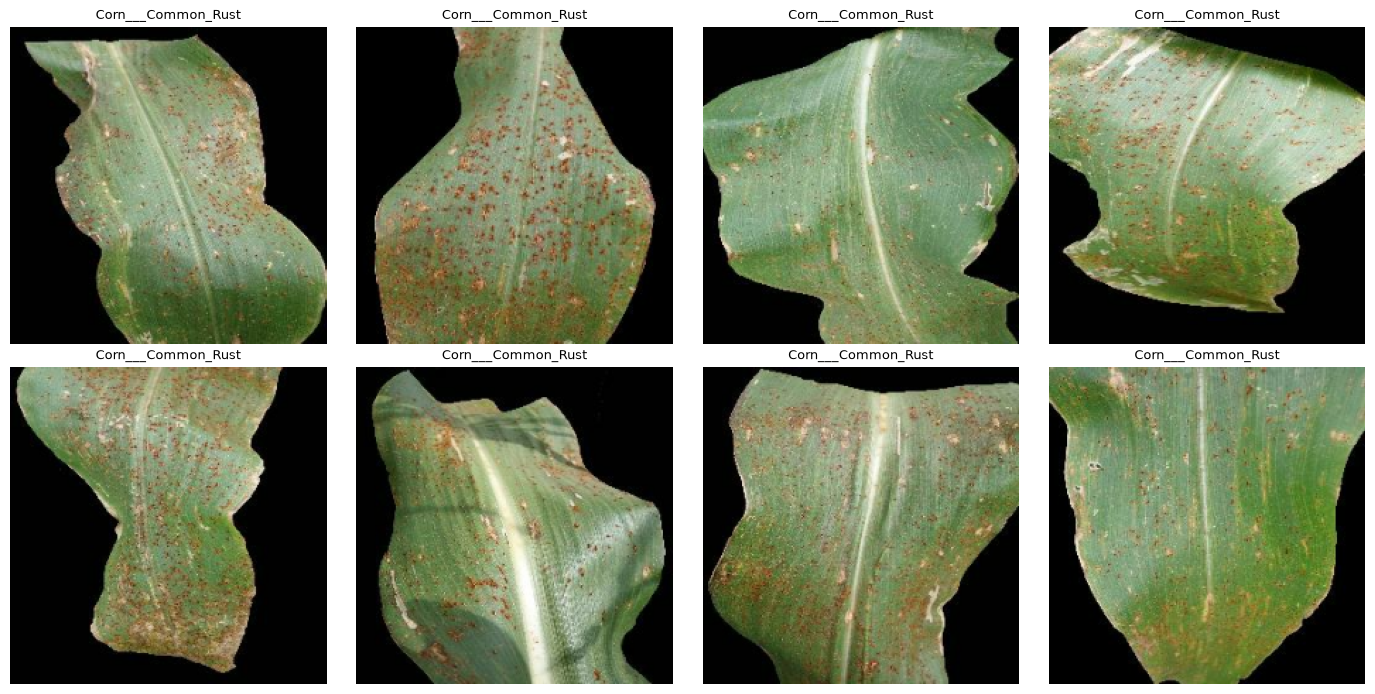

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for idx, ax in enumerate(axes.flat):
    ax.imshow(batch_imgs[idx].numpy())
    ax.set_title(classes[int(batch_lbls[idx])], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()